In [1]:
import pandas as pd
print(pd.__version__)

3.1.0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
print("Done")

Done


In [3]:
# load and Inspect Data

In [4]:
import os
print("Notebook is running in:", os.getcwd())
print("Looking for:", os.path.abspath('../data/raw/Online Retail.xlsx'))
print("File exists:", os.path.exists('../data/raw/Online Retail.xlsx'))

Notebook is running in: C:\Users\palal\Desktop\ecommerce-customer-analysis\notebooks
Looking for: C:\Users\palal\Desktop\ecommerce-customer-analysis\data\raw\Online Retail.xlsx
File exists: True


In [5]:
import os
print(os.getcwd())

C:\Users\palal\Desktop\ecommerce-customer-analysis\notebooks


In [6]:
raw = pd.read_csv('../data/raw/online_retail_raw.csv', parse_dates=['InvoiceDate'], low_memory=False)
raw.to_csv('../data/raw/online_retail_raw.csv', index=False)  # faster to reload later
df = raw.copy()

In [7]:
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [10]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique customers:", df['CustomerID'].nunique())
print("Unique products:", df['StockCode'].nunique())
print("Countries:", df['Country'].nunique())
print("Date range:", df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())

Duplicate rows: 5268
Unique customers: 4372
Unique products: 4070
Countries: 38
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [12]:
df[df['Quantity'] < 0].head()
df[df['UnitPrice'] <= 0].head()
df[df['InvoiceNo'].astype(str).str.startswith('C')].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [13]:
# Cleaning Part 1 (Structure, Types, Duplicates)

In [14]:
cleaning_log = []

def log_step(step_name, data):
    cleaning_log.append({'step': step_name, 'rows_remaining': len(data)})

log_step('Raw data', df)

In [15]:
cleaning_log

[{'step': 'Raw data', 'rows_remaining': 541909}]

In [16]:
pd.DataFrame(cleaning_log)

,step,rows_remaining
0,Raw data,541909


In [17]:
df = df.rename(columns={
    'InvoiceNo': 'invoice_no',
    'StockCode': 'stock_code',
    'Description': 'description',
    'Quantity': 'quantity',
    'InvoiceDate': 'invoice_date',
    'UnitPrice': 'unit_price',
    'CustomerID': 'customer_id',
    'Country': 'country'
})

In [18]:
df['invoice_no'] = df['invoice_no'].astype(str).str.strip()
df['stock_code'] = df['stock_code'].astype(str).str.strip().str.upper()
df['description'] = df['description'].str.strip()
df['country'] = df['country'].str.strip()
df['invoice_date'] = pd.to_datetime(df['invoice_date'])
df['customer_id'] = df['customer_id'].astype('Int64')   # whole numbers, keeps missing values

In [19]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
log_step('Removed duplicates', df)
print("Rows now:", len(df))

Duplicates before: 5268
Rows now: 536641


In [20]:
print(len(cleaning_log))
print(len(df))

2
536641


In [21]:
pd.DataFrame(cleaning_log)

,step,rows_remaining
0,Raw data,541909
1,Removed duplicates,536641


In [22]:
print(df['description'].isnull().sum())

1454


In [23]:
# Not droping Customerid because it is 25% if the data and might be useful in other analysiss

In [24]:
#df.head()
df.info()

<class 'pandas.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   invoice_no    536641 non-null  str           
 1   stock_code    536641 non-null  str           
 2   description   535187 non-null  str           
 3   quantity      536641 non-null  int64         
 4   invoice_date  536641 non-null  datetime64[us]
 5   unit_price    536641 non-null  float64       
 6   customer_id   401604 non-null  Int64         
 7   country       536641 non-null  str           
dtypes: Int64(1), datetime64[us](1), float64(1), int64(1), str(4)
memory usage: 37.4 MB


In [25]:
df['is_cancelled'] = df['invoice_no'].str.startswith('C')
print("Cancelled rows:", df['is_cancelled'].sum())

cancelled = df[df['is_cancelled']]
cancelled.to_csv('../data/cleaned/cancelled_orders.csv', index=False)  # save for optional later analysis

df = df[~df['is_cancelled']].copy()
log_step('Removed cancelled orders', df)


Cancelled rows: 9251


In [26]:
print("Quantity <= 0:", (df['quantity'] <= 0).sum())
print("Unit price <= 0:", (df['unit_price'] <= 0).sum())

df = df[(df['quantity'] > 0) & (df['unit_price'] > 0)]
log_step('Removed quantity/price <= 0', df)

Quantity <= 0: 1336
Unit price <= 0: 2512


In [27]:
df['stock_code'] = df['stock_code'].str.strip().str.upper()
non_product = df[~df['stock_code'].str.match(r'^\d{5}')]
print(non_product['stock_code'].value_counts())

stock_code
POST            1126
DOT              706
M                317
C2               141
DCGSSGIRL         13
BANK CHARGES      12
DCGSSBOY          11
GIFT_0001_20       9
GIFT_0001_10       8
GIFT_0001_30       7
DCGS0003           4
GIFT_0001_50       4
GIFT_0001_40       3
PADS               3
AMAZONFEE          2
DCGS0076           2
S                  2
DCGS0070           1
DCGS0069           1
DCGS0004           1
B                  1
Name: count, dtype: int64


In [28]:
df = df[df['stock_code'].str.match(r'^\d{5}')]
log_step('Removed non-product codes', df)

In [29]:
big_cancel = cancelled[cancelled['quantity'] <= -50000]

orders_to_drop = []
for _, c in big_cancel.iterrows():
    match = df[(df['customer_id'] == c['customer_id']) &
               (df['stock_code'] == c['stock_code']) &
               (df['quantity'] == -c['quantity']) &
               (df['invoice_date'] <= c['invoice_date'])]
    orders_to_drop += match['invoice_no'].tolist()

df[df['invoice_no'].isin(orders_to_drop)][['invoice_no', 'customer_id', 'description', 'quantity', 'unit_price', 'invoice_date']]

,invoice_no,customer_id,description,quantity,unit_price,invoice_date
61619,541431,12346,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00
540421,581483,16446,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00


In [30]:
df = df[~df['invoice_no'].isin(orders_to_drop)]
log_step('Removed fully cancelled bulk orders', df)
print(len(df))

522502


**Two orders of 50,000+ units were fully cancelled within minutes. The cancellation rows were already removed, so the original orders are removed too**

In [31]:
df[['quantity', 'unit_price']].describe()
df.sort_values('quantity', ascending=False).head(10)
df.sort_values('unit_price', ascending=False).head(10)

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.5,15098,United Kingdom,False
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.5,15098,United Kingdom,False
133994,547814,22656,VINTAGE BLUE KITCHEN CABINET,1,2011-03-25 14:19:00,295.0,13452,United Kingdom,False
51636,540647,22655,VINTAGE RED KITCHEN CABINET,1,2011-01-10 14:57:00,295.0,17406,United Kingdom,False
118769,546480,22656,VINTAGE BLUE KITCHEN CABINET,1,2011-03-14 11:38:00,295.0,13452,United Kingdom,False
82768,543253,22655,VINTAGE RED KITCHEN CABINET,1,2011-02-04 15:32:00,295.0,14842,United Kingdom,False
32484,539080,22655,VINTAGE RED KITCHEN CABINET,1,2010-12-16 08:41:00,295.0,16607,United Kingdom,False
4989,536835,22655,VINTAGE RED KITCHEN CABINET,1,2010-12-02 18:06:00,295.0,13145,United Kingdom,False
205759,554836,22655,VINTAGE RED KITCHEN CABINET,1,2011-05-26 16:25:00,295.0,13015,United Kingdom,False
171178,551393,22656,VINTAGE BLUE KITCHEN CABINET,1,2011-04-28 12:22:00,295.0,14973,United Kingdom,False


In [32]:
df['country'].value_counts()

country
United Kingdom          478836
Germany                   8643
France                    8085
EIRE                      7768
Spain                     2417
Netherlands               2322
Belgium                   1935
Switzerland               1927
Portugal                  1455
Australia                 1180
Norway                    1048
Channel Islands            743
Italy                      741
Finland                    647
Cyprus                     601
Unspecified                442
Sweden                     427
Austria                    384
Denmark                    367
Poland                     325
Japan                      321
Israel                     292
Hong Kong                  275
Singapore                  215
Iceland                    182
USA                        179
Canada                     150
Greece                     142
Malta                      109
United Arab Emirates        67
European Community          57
RSA                         57


In [33]:
pd.DataFrame(cleaning_log)

,step,rows_remaining
0,Raw data,541909
1,Removed duplicates,536641
2,Removed cancelled orders,527390
3,Removed quantity/price <= 0,524878
4,Removed non-product codes,522504
5,Removed fully cancelled bulk orders,522502


In [34]:
print(len(df))
print(df['quantity'].min(), df['unit_price'].min())
print(df['invoice_no'].str.startswith('C').sum())
print(df['stock_code'].str.match(r'^\d{5}').all())
pd.DataFrame(cleaning_log)

522502
1 0.04
0
True


,step,rows_remaining
0,Raw data,541909
1,Removed duplicates,536641
2,Removed cancelled orders,527390
3,Removed quantity/price <= 0,524878
4,Removed non-product codes,522504
5,Removed fully cancelled bulk orders,522502


In [35]:
# FEATURE ENGINEERING 

In [36]:
# CREATE THE REVENUE COLUMN

In [37]:
df['total_price'] = (df['quantity'] * df['unit_price']).round(2)


In [38]:
df[['quantity', 'unit_price', 'total_price']].head()

,quantity,unit_price,total_price
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [39]:
# CREATE DATE FEATURES

In [40]:
df['order_date'] = df['invoice_date'].dt.normalize()
df['year'] = df['invoice_date'].dt.year
df['month'] = df['invoice_date'].dt.month
df['order_month'] = df['invoice_date'].dt.to_period('M').astype(str)
df['day_name'] = df['invoice_date'].dt.day_name()
df['hour'] = df['invoice_date'].dt.hour

In [41]:
df[['invoice_date', 'order_date', 'year', 'month', 'order_month', 'day_name', 'hour']].head()

,invoice_date,order_date,year,month,order_month,day_name,hour
0,2010-12-01 08:26:00,2010-12-01,2010,12,2010-12,Wednesday,8
1,2010-12-01 08:26:00,2010-12-01,2010,12,2010-12,Wednesday,8
2,2010-12-01 08:26:00,2010-12-01,2010,12,2010-12,Wednesday,8
3,2010-12-01 08:26:00,2010-12-01,2010,12,2010-12,Wednesday,8
4,2010-12-01 08:26:00,2010-12-01,2010,12,2010-12,Wednesday,8


In [42]:
df = df.drop(columns=['is_cancelled'])
df = df.reset_index(drop=True)
log_step('Final cleaned data', df)

In [43]:
assert df['quantity'].min() > 0
assert df['unit_price'].min() > 0
assert df['total_price'].min() > 0
assert df.duplicated().sum() == 0
assert df['invoice_no'].str.startswith('C').sum() == 0
print("All checks passed ✅")

print(df.isnull().sum())        # only customer_id should have missing values
print(df.dtypes)

All checks passed ✅
invoice_no           0
stock_code           0
description          0
quantity             0
invoice_date         0
unit_price           0
customer_id     131354
country              0
total_price          0
order_date           0
year                 0
month                0
order_month          0
day_name             0
hour                 0
dtype: int64
invoice_no                 str
stock_code                 str
description                str
quantity                 int64
invoice_date    datetime64[us]
unit_price             float64
customer_id              Int64
country                    str
total_price            float64
order_date      datetime64[us]
year                     int32
month                    int32
order_month                str
day_name                   str
hour                     int32
dtype: object


In [44]:
pd.DataFrame(cleaning_log)

,step,rows_remaining
0,Raw data,541909
1,Removed duplicates,536641
2,Removed cancelled orders,527390
3,Removed quantity/price <= 0,524878
4,Removed non-product codes,522504
5,Removed fully cancelled bulk orders,522502
6,Final cleaned data,522502


In [45]:
df.to_csv('../data/cleaned/online_retail_cleaned.csv', index=False)

In [46]:
import os
print(os.path.exists('../data/cleaned/online_retail_cleaned.csv'))

True


In [47]:
# “Step 3: Sanity-check EDA”.

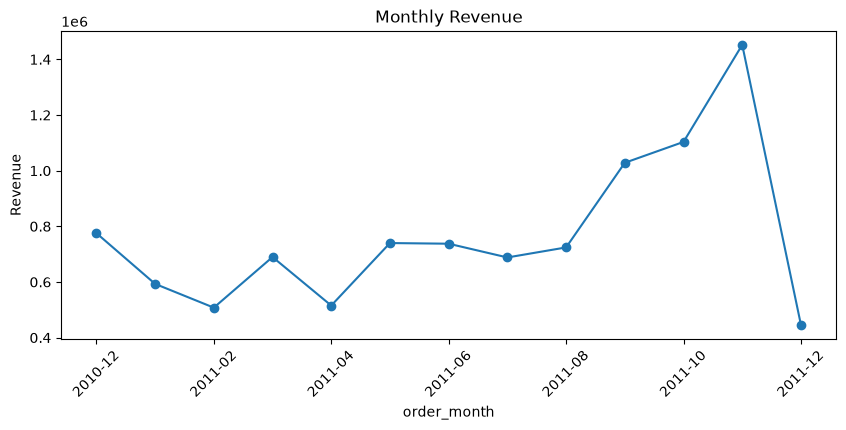

In [48]:
# Monthly revenue
monthly = df.groupby('order_month')['total_price'].sum()
monthly.plot(kind='line', marker='o', figsize=(10,4), title='Monthly Revenue')
plt.ylabel('Revenue'); plt.xticks(rotation=45); plt.show()

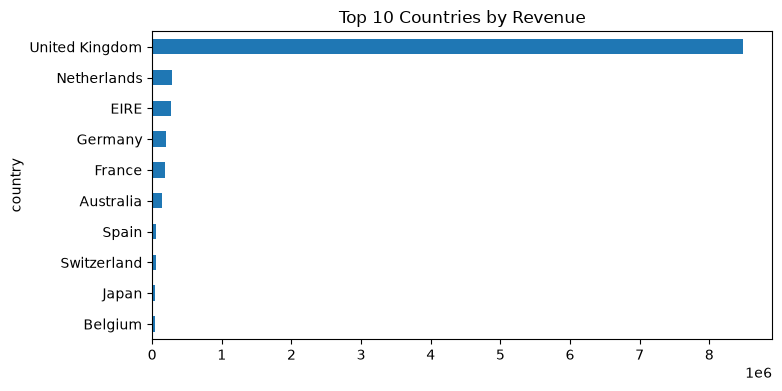

In [49]:
# Top 10 countries by revenue
df.groupby('country')['total_price'].sum().sort_values(ascending=False).head(10)\
  .plot(kind='barh', figsize=(8,4), title='Top 10 Countries by Revenue')
plt.gca().invert_yaxis(); plt.show()

In [50]:
# Top 10 products by revenue
df.groupby('description')['total_price'].sum().sort_values(ascending=False).head(10)

description
REGENCY CAKESTAND 3 TIER              174156.54
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
SPOTTY BUNTING                         42513.48
JUMBO BAG PINK POLKADOT                42401.01
Name: total_price, dtype: float64

<Axes: title={'center': 'Orders by Hour'}, xlabel='hour'>

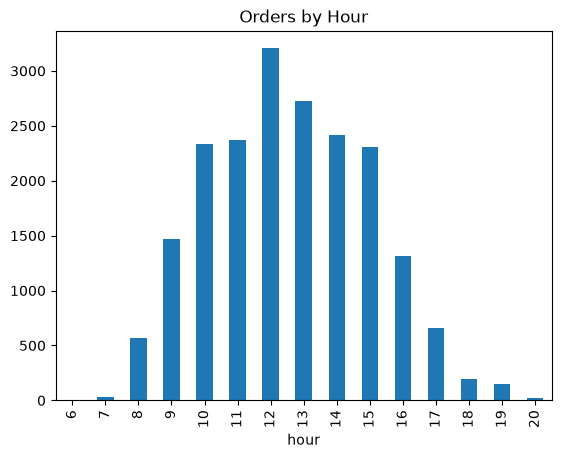

In [51]:
# Orders by day of week and hour
df.groupby('day_name')['invoice_no'].nunique()
df.groupby('hour')['invoice_no'].nunique().plot(kind='bar', title='Orders by Hour')

In [54]:
# Key numbers
print("Total revenue:", df['total_price'].sum().round(2))
print("Total orders:", df['invoice_no'].nunique())
print("Unique customers:", df['customer_id'].nunique())
print("Average order value:", (df.groupby('invoice_no')['total_price'].sum().mean()).round(2))

Total revenue: 10001167.67
Total orders: 19771
Unique customers: 4333
Average order value: 505.85


In [53]:
pd.DataFrame(cleaning_log)

,step,rows_remaining
0,Raw data,541909
1,Removed duplicates,536641
2,Removed cancelled orders,527390
3,Removed quantity/price <= 0,524878
4,Removed non-product codes,522504
5,Removed fully cancelled bulk orders,522502
6,Final cleaned data,522502
